In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
from google.colab import files
uploaded = files.upload()
df = pd.read_csv("diabetes.csv")

Saving diabetes.csv to diabetes (2).csv


In [ ]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
print(df.shape)
print(df.columns)
print(df.info())

(768, 9)
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None


In [ ]:
print(df.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


The Pima Indians Diabetes Dataset was successfully loaded using Pandas. It contains 768 records and 9 columns, providing information about patient characteristics and diabetes outcomes.

In [ ]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

In [ ]:
print("Features: ")
print(X.columns)
print("\nTarget: ")
print(y.name)

Features: 
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age'],
      dtype='object')

Target: 
Outcome


The eight independent variables were separated from the dependent variable, Outcome. The independent variables are used to predict whether a patient has diabetes, while Outcome represents the target class, where 0 indicates no diabetes and 1 indicates diabetes.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
print("Training data: ")
print(X_train.shape)
print(y_train.shape)
print("\nTesting data: ")
print(X_test.shape)
print(y_test.shape)

Training data: 
(614, 8)
(614,)

Testing data: 
(154, 8)
(154,)


The dataset was divided into 614 training records and 154 testing records using an 80:20 ratio. The training set is used to train the classifier, while the testing set evaluates its performance on unseen data.

In [ ]:
model = DecisionTreeClassifier(criterion="entropy", random_state=42)
model.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', random_state=42)

In [ ]:
y_pred = model.predict(X_test)

The Decision Tree Classifier was trained using the entropy criterion. The algorithm selects splitting conditions that reduce uncertainty in the target variable and develops decision rules for classifying diabetic and non-diabetic cases.

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy: ", accuracy)

Accuracy:  0.7012987012987013


In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.75      0.80      0.78       100
           1       0.58      0.52      0.55        54

    accuracy                           0.70       154
   macro avg       0.67      0.66      0.66       154
weighted avg       0.69      0.70      0.70       154



In [ ]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix: ")
print(cm)

Confusion Matrix: 
[[80 20]
 [26 28]]


The confusion matrix shows that 80 non-diabetic cases and 28 diabetic cases were correctly classified. However, 20 non-diabetic cases were incorrectly classified as diabetic, and 26 diabetic cases were incorrectly classified as non-diabetic. This highlights the need to improve the model's ability to identify diabetic cases.

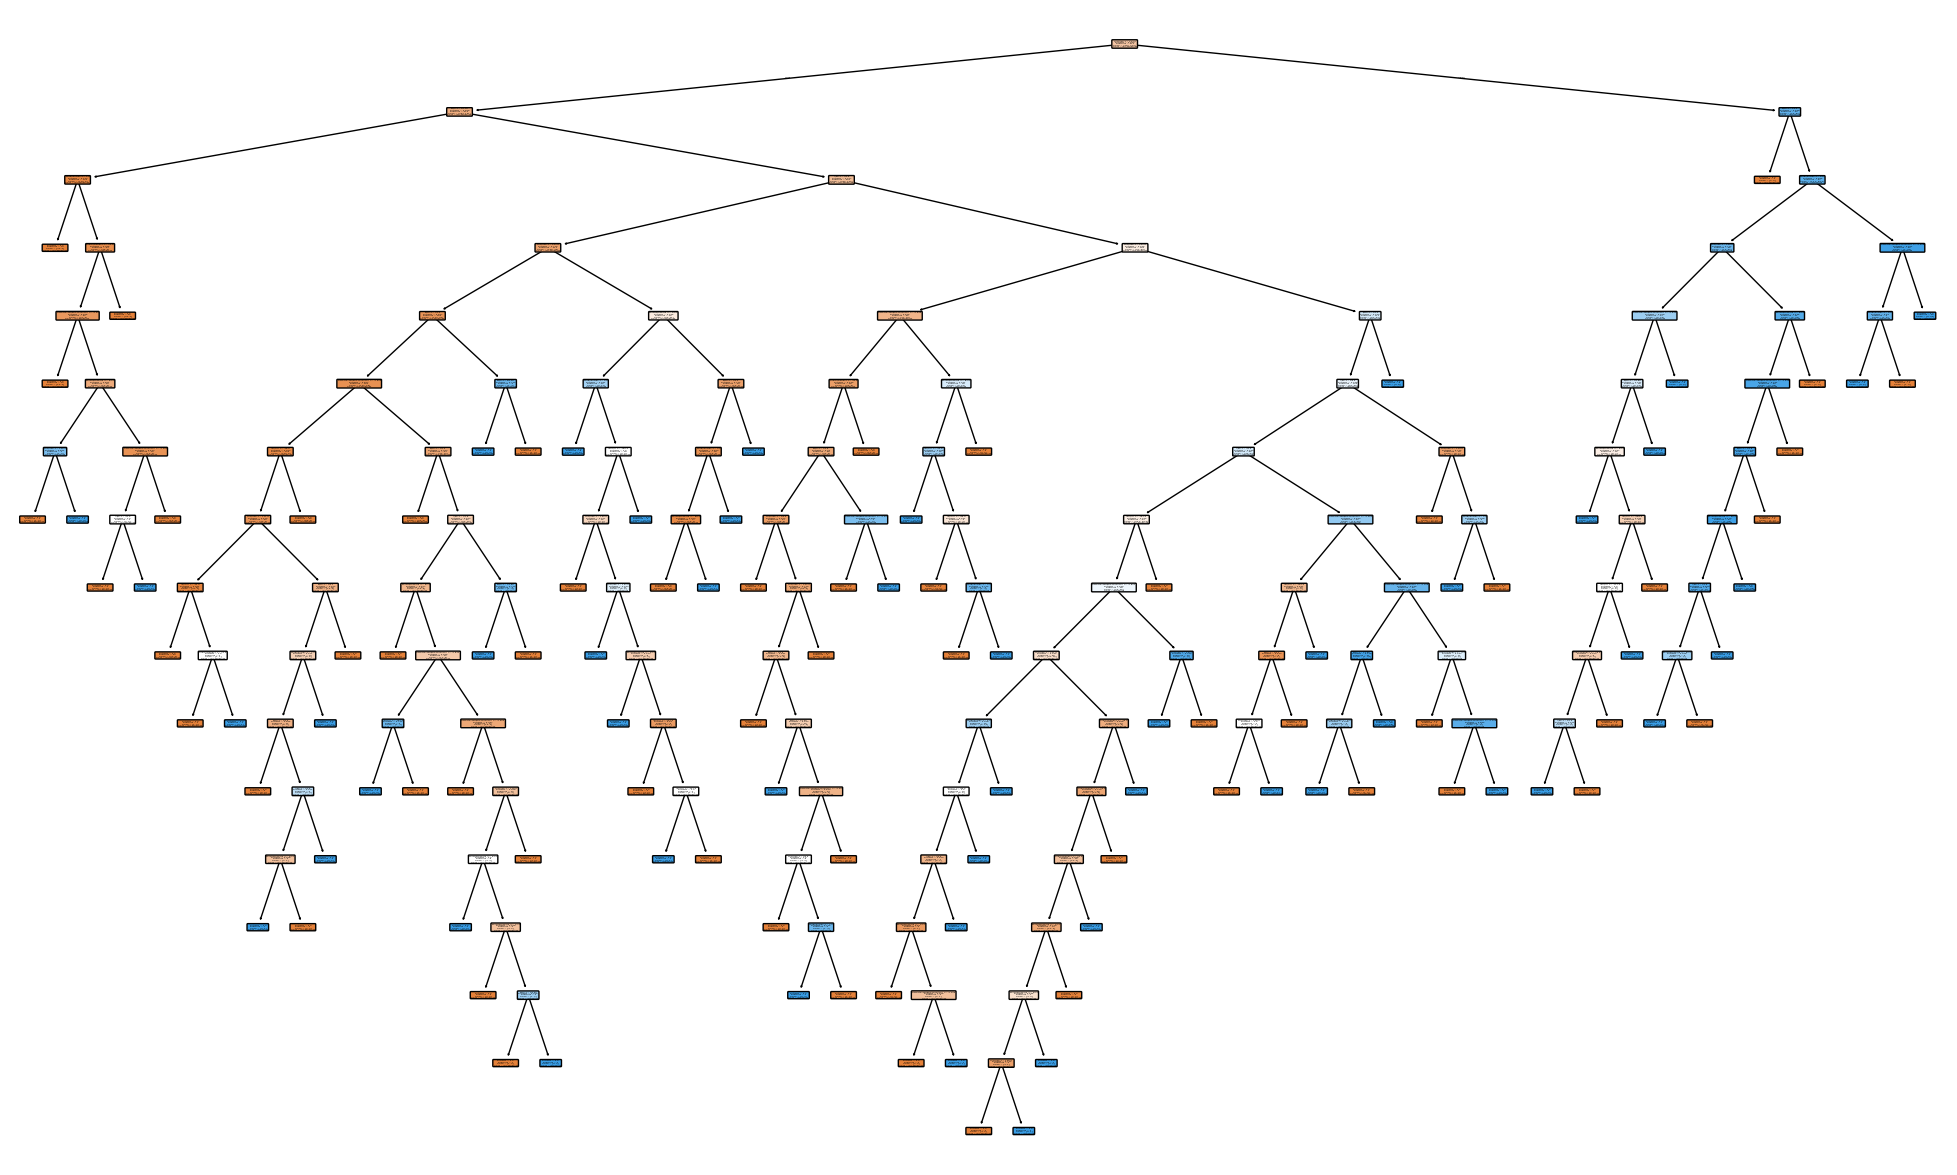

In [ ]:
plt.figure(figsize=(25, 15))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    rounded=True
)
plt.show()

The decision tree visualization displays the hierarchy of feature-based decisions made by the classifier. Each internal node represents a condition, branches represent the outcomes of that condition, and leaf nodes represent the final classifications. The root node is the first feature used to divide the dataset.

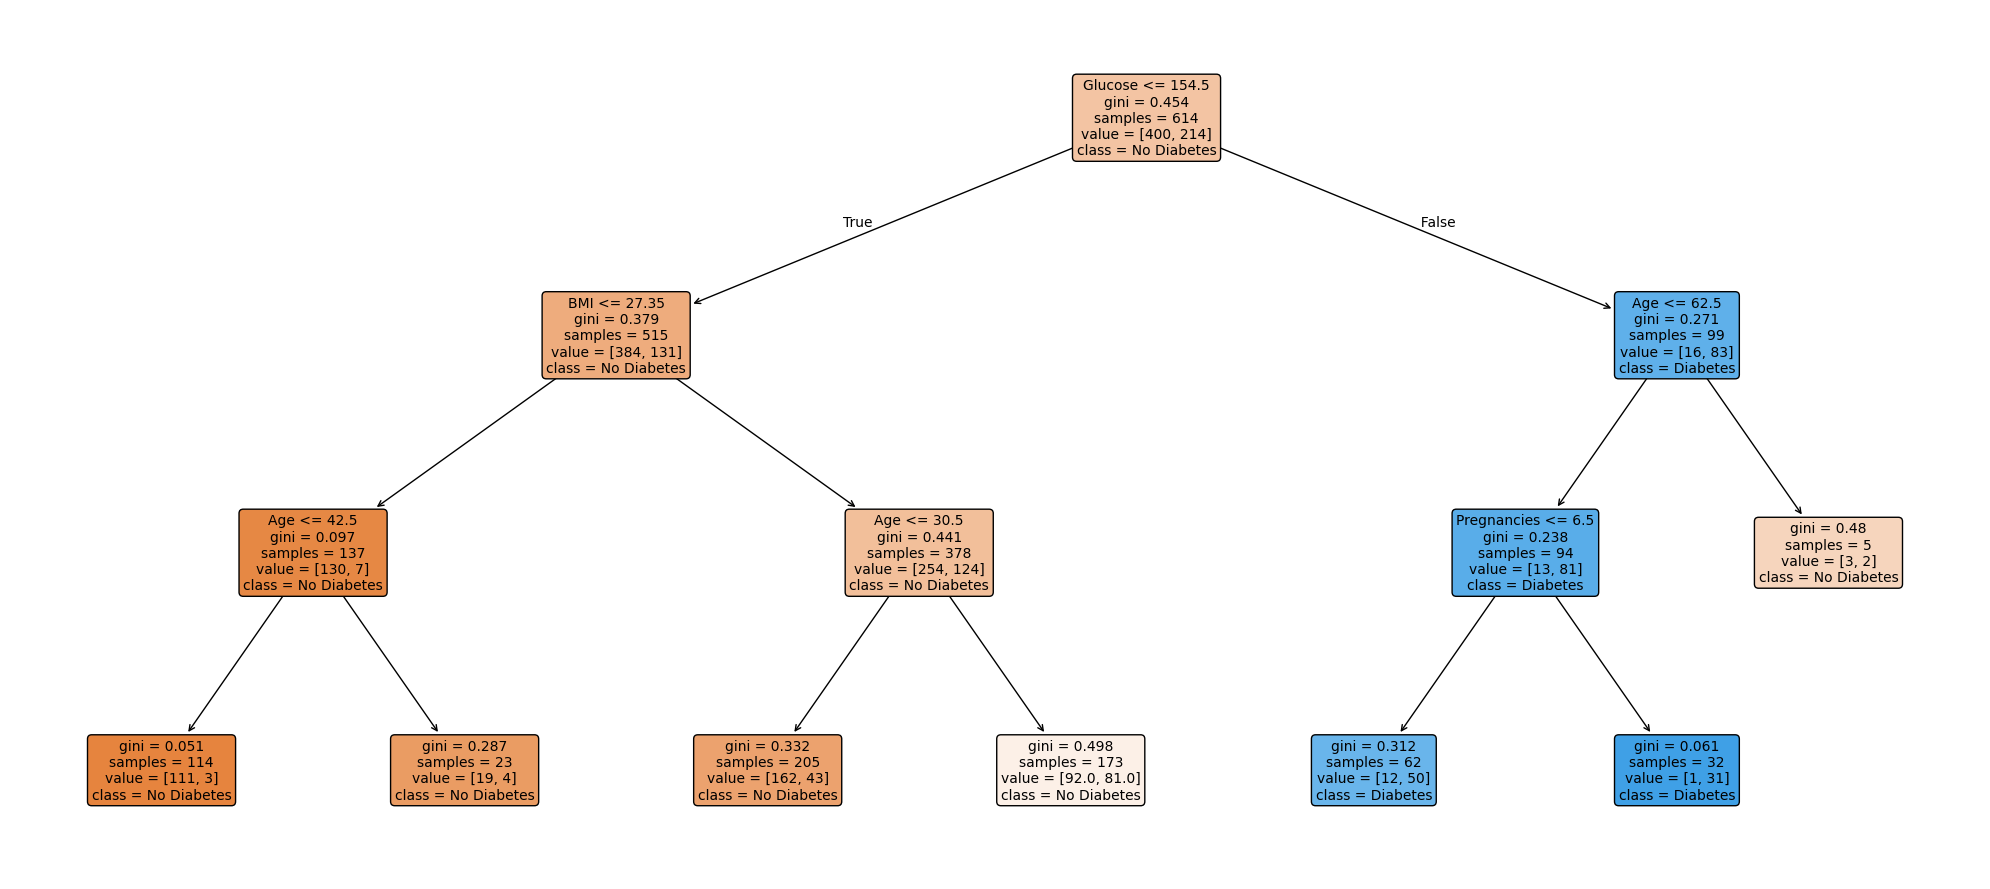

In [ ]:
model = DecisionTreeClassifier(
    max_depth=3,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

model.fit(X_train, y_train)

plt.figure(figsize=(20, 9))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.tight_layout()
plt.show()

# Entropy

In [ ]:
from sklearn.metrics import log_loss
def entropy(y):
  probabilities = y.value_counts(normalize=True)

  return -sum(
      p * np.log2(p)
      for p in probabilities
      if p > 0
  )
dataset_entropy = entropy(y)
print("Entropy of dataset: ", dataset_entropy)

Entropy of dataset:  0.9331343166407831


The entropy of the complete dataset is approximately 0.9331 bits. Entropy measures the uncertainty or impurity in the target classes. The value indicates that the dataset contains a mixture of diabetic and non-diabetic cases rather than records belonging to a single class.

# Information Gain

In [ ]:
from sklearn.feature_selection import mutual_info_classif
mi = mutual_info_classif(X, y, random_state=42)
information_gain = pd.Series(mi, index=X.columns).sort_values(ascending=False)
print("Information gain: ",information_gain)


Information gain:  Glucose                     0.114634
BMI                         0.080061
Pregnancies                 0.060985
Age                         0.051395
DiabetesPedigreeFunction    0.014590
Insulin                     0.011948
SkinThickness               0.004667
BloodPressure               0.000000
dtype: float64


Information Gain measures the reduction in entropy obtained by splitting the dataset using a feature. A higher value indicates that the feature provides more information for predicting the target variable. In the feature relevance analysis, Glucose has the highest estimated mutual information value of approximately 0.1146, followed by BMI at approximately 0.0801.

In [ ]:
root_index = model.tree_.feature[0]
root_feature = X.columns[root_index]
root_threshold = model.tree_.threshold[0]
print("Root Feature: ", root_feature)
print("Root Threshold: ", root_threshold)

Root Feature:  Glucose
Root Threshold:  154.5


The entropy-based Decision Tree selected Glucose as the root feature, with a splitting threshold of 154.5. The first split separates records with glucose values less than or equal to 154.5 from those with values greater than 154.5. This feature provides the best split among the candidate splits considered by the trained model.

# Gini Index

In [ ]:
def gini(y):
  probabilities = y.value_counts(normalize=True)

  return 1 - sum(p**2 for p in probabilities)
dataset_gini = gini(y)
print("Gini Index of dataset: ", dataset_gini)

Gini Index of dataset:  0.45437282986111116


The Gini Index of the complete dataset is approximately 0.4544. It measures the impurity of the target classes. A lower Gini value indicates a more homogeneous group, while a value of zero indicates that all records belong to the same class.

In [ ]:
entropy_tree = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)
entropy_tree.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', random_state=42)

In [ ]:
gini_tree = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)
gini_tree.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [ ]:
entropy_root = X.columns[entropy_tree.tree_.feature[0]]
entropy_threshold = entropy_tree.tree_.threshold[0]
gini_root = X.columns[gini_tree.tree_.feature[0]]
gini_threshold = gini_tree.tree_.threshold[0]

print("Entropy Root: ", entropy_root)
print("Entropy Threshold: ", entropy_threshold)
print("Gini Root: ", gini_root)
print("Gini Threshold: ", gini_threshold)

Entropy Root:  Glucose
Entropy Threshold:  154.5
Gini Root:  Glucose
Gini Threshold:  154.5


Both the entropy-based and Gini-based classifiers selected Glucose as the root feature, with a threshold of 154.5. The entropy-based tree achieved 70.13% accuracy, while the Gini-based tree achieved 72.73% accuracy on the same testing set. Therefore, the Gini-based tree performed slightly better on this particular test set.

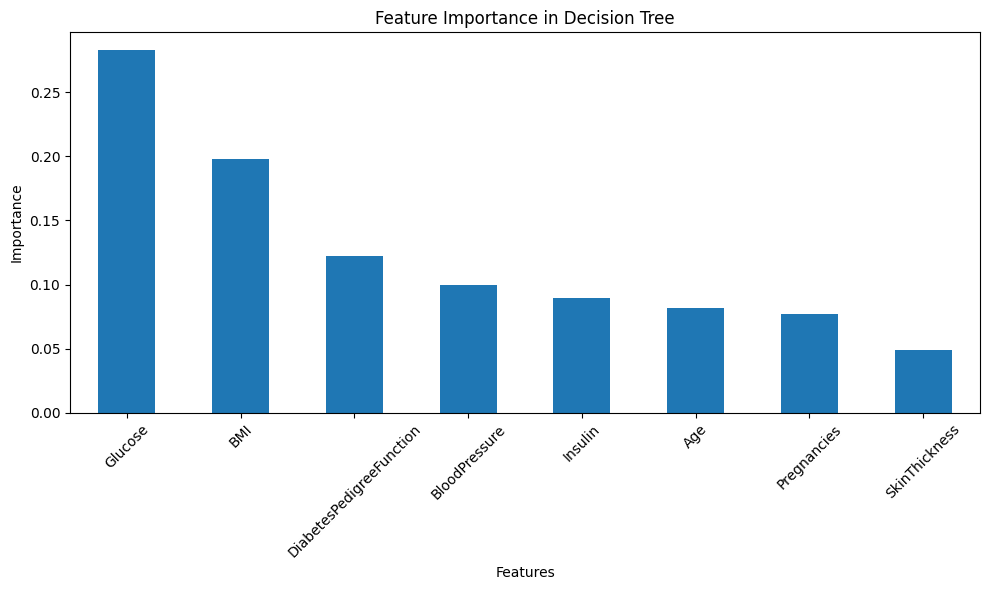

In [ ]:
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)
plt.figure(figsize=(10, 6))
importance.plot(kind="bar")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature Importance in Decision Tree")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The feature importance graph shows the relative contribution of each feature to the entropy-based decision tree. Glucose has the highest importance, approximately 0.283, followed by BMI at approximately 0.198. SkinThickness has the lowest importance, approximately 0.049. This indicates that Glucose contributed the most to the model's splitting decisions.

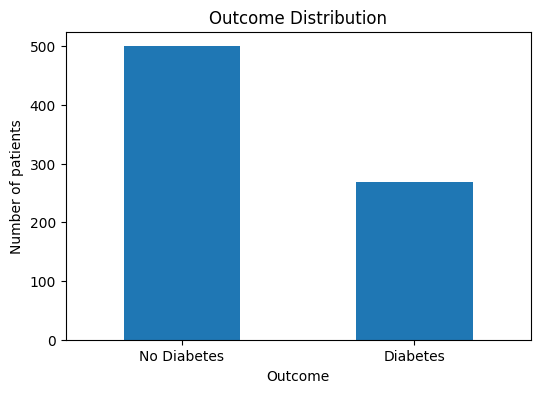

In [ ]:
plt.figure(figsize=(6, 4))
df["Outcome"].value_counts().plot(kind="bar")
plt.xlabel("Outcome")
plt.ylabel("Number of patients")
plt.title("Outcome Distribution")
plt.xticks(
    [0, 1],
    ["No Diabetes", "Diabetes"],
    rotation=0
)
plt.show()


The outcome distribution graph represents the number of diabetic and non-diabetic individuals in the dataset. It shows that 500 individuals belong to Outcome 0 (No Diabetes), while 268 individuals belong to Outcome 1 (Diabetes). Therefore, the dataset contains more non-diabetic individuals than diabetic individuals, indicating a class imbalance in the dataset.